# Customer Churn Prediction (Kundenbindungsanalyse)

## Projektüberblick

Customer Churn ,also die Abwanderung von Kunden, ist für viele Unternehmen ein zentrales wirtschaftliches Thema. Schon geringe Veränderungen in der Kundenbindung können sich spürbar auf Umsatz, Wachstum und langfristige Profitabilität auswirken.

In diesem Projekt habe ich mich mit der Frage beschäftigt, **welche Kunden mit hoher Wahrscheinlichkeit abwandern** und **welche Faktoren dabei eine entscheidende Rolle spielen**. Ziel war es nicht nur, ein möglichst gutes Vorhersagemodell zu entwickeln, sondern die Ergebnisse auch so aufzubereiten, dass sie für das Kundenmanagement praktisch nutzbar sind.


## Zielsetzung

Konkret verfolge ich in diesem Projekt folgende Ziele:

- Aufbau eines **binären Klassifikationsmodells** zur Vorhersage von Customer Churn  
- Identifikation und Analyse der **wichtigsten Einflussfaktoren** (z. B. demografische, vertragliche und nutzungsbezogene Merkmale)  
- Vergleich unterschiedlicher **Machine-Learning-Modelle** hinsichtlich Performance und Interpretierbarkeit  
- Ableitung von **datenbasierten Handlungsempfehlungen**, die zur Reduzierung der Abwanderungsrate beitragen können


In [2]:
import pandas as pd
df = pd.read_csv('customer_churn_dataset-testing-master.csv')
print(df.shape)
df.head()

(64374, 12)


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


## Datensatzbeschreibung

Der Datensatz umfasst **64.374 Kundenbeobachtungen** mit insgesamt **12 Merkmalen** und bildet unterschiedliche Aspekte der Kundenbeziehung ab.

Enthalten sind unter anderem Informationen zu:
- **demografischen Eigenschaften** (z. B. Alter, Geschlecht),
- **Vertrags- und Abonnementmerkmalen**,
- dem **Nutzungs- und Interaktionsverhalten** der Kunden,
- sowie **Zahlungs- und Umsatzdaten**.

Die Zielvariable **`Churn`** ist binär definiert:
- `0` → Kunde bleibt beim Unternehmen  
- `1` → Kunde hat die Beziehung beendet  

Der Datensatz enthält sowohl **numerische** als auch **kategoriale Variablen** und eignet sich damit gut für eine explorative Analyse sowie für den Einsatz verschiedener Klassifikationsmodelle.


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 5.9+ MB


## Erste Datenübersicht

Nach dem Laden der Daten habe ich zunächst eine grundlegende Übersicht erstellt. Dabei zeigte sich, dass der Datensatz vollständig ist und **keine fehlenden Werte** enthält, was die weitere Analyse deutlich vereinfacht.

Insgesamt liegen **9 numerische** und **3 kategoriale Variablen** vor. Der vergleichsweise moderate Speicherbedarf ermöglicht eine effiziente explorative Analyse sowie die anschließende Modellierung ohne technische Einschränkungen.


In [4]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


## Deskriptive Statistik

Die deskriptive Analyse der numerischen Variablen zeigt, dass sich alle Werte in **plausiblen Bereichen** bewegen. Auffällige Extremwerte oder offensichtliche Inkonsistenzen konnten dabei nicht festgestellt werden.

Auch die Zielvariable **`Churn`** ist moderat verteilt und weist **keine starke Klassenungleichverteilung** auf. Damit sind grundsätzlich gute Voraussetzungen für die anschließende Modellierung gegeben, ohne dass zunächst aufwendige Maßnahmen zum Klassenbalancing erforderlich sind.

Auch wenn der Datensatz synthetisch erzeugt wurde, bildet er viele realistische Muster ab und lässt sich sinnvoll für die Entwicklung und den Vergleich von Modellen nutzen.


## Methodischer Ansatz

Für die Analyse habe ich mich an einem klassischen Data-Science-Vorgehen orientiert. Der Projektablauf gliedert sich in folgende Schritte:

1. Explorative Datenanalyse (EDA)  
2. Datenvorverarbeitung und Feature Engineering  
3. Modellierung mit verschiedenen Klassifikationsverfahren  
4. Bewertung der Modelle anhand geeigneter Metriken  
5. Interpretation der Ergebnisse und Ableitung von Handlungsempfehlungen


## Explorative Datenanalyse (EDA)

In der explorativen Datenanalyse habe ich mir zunächst einen Überblick über die Daten verschafft und untersucht, ob sich erste Muster im Zusammenhang mit der Kundenabwanderung erkennen lassen.

Im Fokus standen dabei vor allem Unterschiede zwischen churnenden und nicht churnenden Kunden sowie mögliche Zusammenhänge zwischen numerischen und kategorialen Merkmalen.

Die Ergebnisse dieser Analyse bilden die Grundlage für die anschließende Feature-Auswahl und Modellierung.


### Verteilung der Zielvariable

Zu Beginn habe ich mir die Verteilung der Zielvariable `Churn` angesehen, um ein mögliches Klassenungleichgewicht frühzeitig zu erkennen.

Diese Einschätzung ist wichtig für die spätere Modellierung und die Wahl geeigneter Bewertungsmetriken.


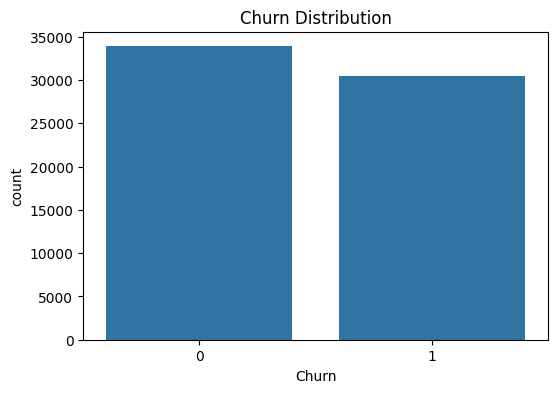

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

**Beobachtung:**

Die Zielvariable weist eine **relativ ausgewogene Klassenverteilung** zwischen churnenden und nicht churnenden Kunden auf.

**Einordnung:**

Da kein starkes Klassenungleichgewicht vorliegt, können klassische Klassifikationsmodelle ohne zusätzliche Maßnahmen zum Klassenbalancing eingesetzt werden. Entsprechend habe ich zunächst auf spezielle Techniken wie Over- oder Undersampling verzichtet.


### Korrelationen zwischen numerischen Merkmalen

Im nächsten Schritt habe ich die linearen Zusammenhänge zwischen den numerischen Merkmalen sowie deren Beziehung zur Zielvariable `Churn` untersucht.

Die Korrelationsanalyse dient hier als erste Orientierung und liefert Hinweise auf potenziell relevante Einflussfaktoren, ohne eine kausale Interpretation vorwegzunehmen.


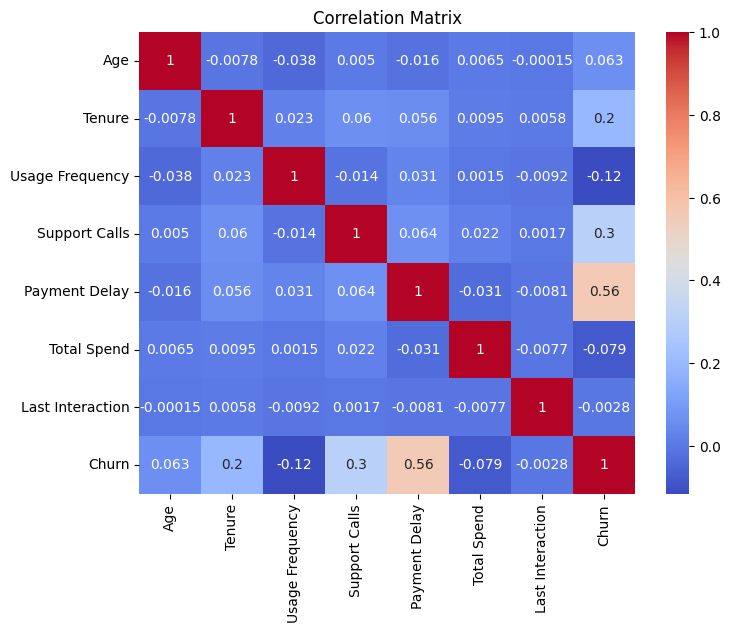

In [6]:
num_cols = [
    'Age', 'Tenure', 'Usage Frequency', 
    'Support Calls', 'Payment Delay', 
    'Total Spend', 'Last Interaction', 'Churn'
]

corr = df[num_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)
plt.title("Correlation Matrix")
plt.show()


**Beobachtungen:**

- `Payment Delay` zeigt eine deutliche positive Korrelation mit `Churn`.
- Auch die Anzahl der `Support Calls` ist moderat positiv mit der Abwanderung korreliert.
- `Usage Frequency` und `Total Spend` weisen hingegen eine negative Korrelation mit `Churn` auf.
- Zwischen den meisten numerischen Merkmalen bestehen nur geringe lineare Zusammenhänge untereinander.

**Einordnung:**

Zahlungsverzögerungen und häufige Support-Anfragen erscheinen als klare Hinweise auf eine erhöhte Abwanderungswahrscheinlichkeit. Umgekehrt deuten eine hohe Nutzungshäufigkeit und höhere Ausgaben auf eine stärkere Kundenbindung hin.

Da die Korrelationsanalyse nur lineare Beziehungen abbildet, habe ich im weiteren Verlauf bewusst auch nichtlineare Modelle berücksichtigt.


### Analyse numerischer Merkmale im Zusammenhang mit Churn

Im nächsten Schritt habe ich ausgewählte numerische Merkmale hinsichtlich ihrer Verteilung bei churnenden und nicht churnenden Kunden verglichen.

Zur Visualisierung der Unterschiede in Lage und Streuung habe ich Boxplots verwendet, die auch potenzielle Ausreißer sichtbar machen.


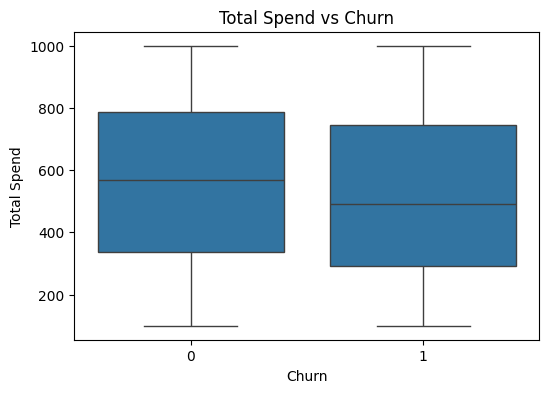

In [7]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='Total Spend', data=df)
plt.title('Total Spend vs Churn')
plt.show()

**Beobachtung:**

Nicht churnende Kunden weisen im Median einen höheren Gesamtumsatz auf als churnende Kunden, auch wenn sich die Verteilungen teilweise überlappen.

**Einordnung:**

Ein höherer Gesamtumsatz geht tendenziell mit einer geringeren Abwanderungswahrscheinlichkeit einher. Der Zusammenhang ist erkennbar, aber insgesamt eher moderat ausgeprägt.


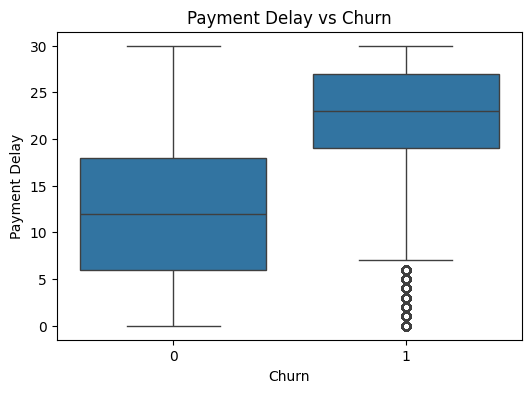

In [8]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='Payment Delay', data=df)
plt.title('Payment Delay vs Churn')
plt.show()

**Beobachtung:**

Churnende Kunden zeigen deutlich höhere Zahlungsverspätungen. Der Median sowie das obere Quartil liegen signifikant über denen der nicht churnenden Kunden. Vereinzelt treten niedrige Ausreißer bei churnenden Kunden auf.

**Interpretation:**

Zahlungsverzögerungen sind ein starker Indikator für Kundenabwanderung. Die beobachteten Ausreißer stellen plausible Geschäftsfälle dar und deuten nicht auf Datenqualitätsprobleme hin.


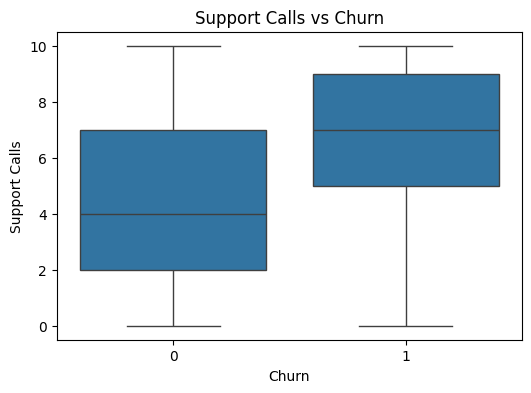

In [9]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='Support Calls', data=df)
plt.title('Support Calls vs Churn')
plt.show()

**Beobachtung:**

Churnende Kunden kontaktieren den Support im Median häufiger als nicht churnende Kunden.
Die Verteilung ist bei churnenden Kunden insgesamt nach oben verschoben.

**Interpretation:**

Eine hohe Anzahl an Support-Anfragen deutet auf Unzufriedenheit oder Probleme im Kundenverhältnis hin und ist ein relevanter
Churn-Treiber.


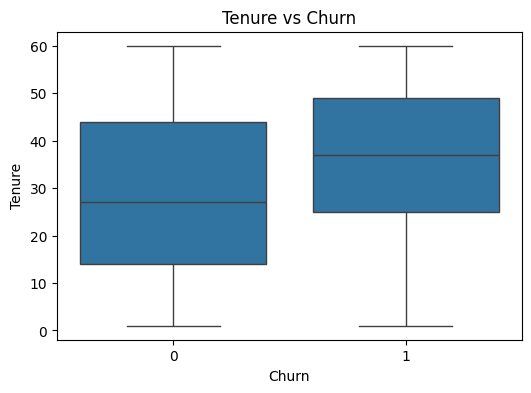

In [10]:
plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='Tenure', data=df)
plt.title('Tenure vs Churn')
plt.show()

**Beobachtung:**

Nicht churnende Kunden weisen eine größere Streuung der Vertragslaufzeit auf. Der Interquartilsabstand ist in dieser Gruppe breiter als bei churnenden Kunden.

**Einordnung:**

Die Vertragslaufzeit allein scheint kein eindeutiger Schutz vor Abwanderung zu sein. Während churnende Kunden stärker im mittleren Bereich konzentriert sind, zeigt sich bei nicht churnenden Kunden eine höhere Heterogenität in der Vertragsdauer.


**Zwischenfazit:**

Insbesondere Zahlungsverspätungen und die Anzahl der Support-Anfragen zeigen deutliche Unterschiede zwischen churnenden und nicht churnenden Kunden. Diese Merkmale habe ich daher als besonders relevante Kandidaten für die anschließende Modellierung betrachtet.


### Analyse kategorialer Merkmale im Zusammenhang mit Churn

Im nächsten Schritt habe ich untersucht, wie sich die Abwanderungsrate zwischen den einzelnen Ausprägungen kategorialer Merkmale unterscheidet.

Dazu habe ich jeweils die durchschnittliche Churn-Rate pro Kategorie betrachtet, um potenziell relevante Einflussfaktoren übersichtlich einordnen zu können.


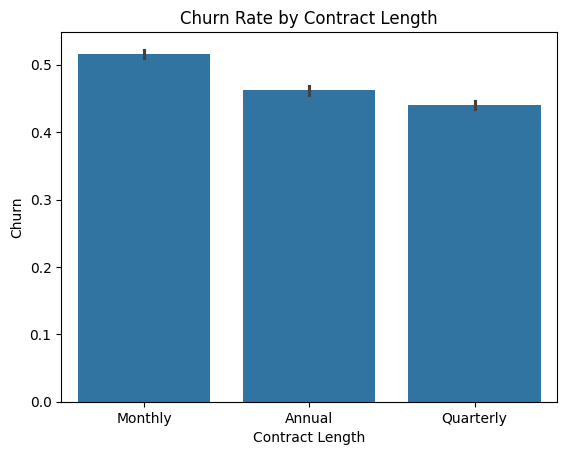

In [11]:
sns.barplot(x='Contract Length', y='Churn', data=df)
plt.title('Churn Rate by Contract Length')
plt.show()


**Beobachtung:**

Kunden mit monatlichen Verträgen weisen die höchste Churn-Rate auf. Mit zunehmender Vertragslaufzeit sinkt die Abwanderungsrate deutlich.

**Einordnung:**

Längere Vertragsbindungen scheinen stabilisierend auf das Kundenverhältnis zu wirken. Monatliche Verträge sind mit einem erhöhten Abwanderungsrisiko verbunden und stellen damit einen relevanten Ansatzpunkt für Retention-Maßnahmen dar.


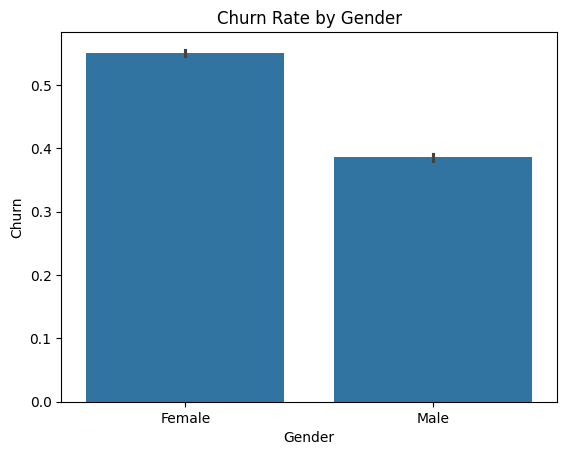

In [12]:
sns.barplot(x='Gender', y='Churn',data=df)
plt.title('Churn Rate by Gender')
plt.show()

**Beobachtung:**

Die Churn-Rate unterscheidet sich zwischen den Geschlechtern. In diesem Datensatz weisen weibliche Kunden eine höhere Abwanderungsrate auf als männliche Kunden.

**Einordnung:**

Das Geschlecht scheint hier mit dem Abwanderungsverhalten zusammenzuhängen. Der Effekt sollte im weiteren Verlauf der Modellierung berücksichtigt und im Zusammenspiel mit anderen Merkmalen genauer geprüft werden.


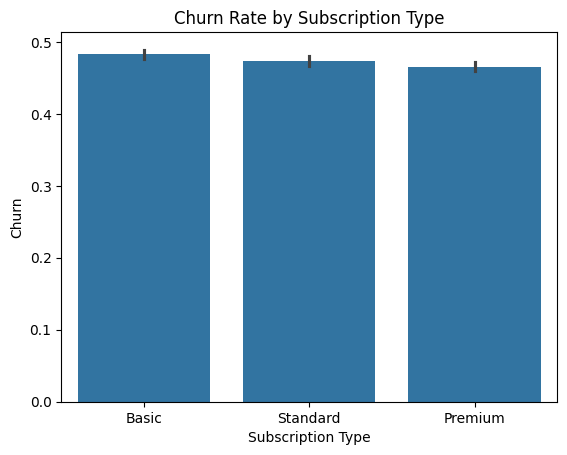

In [13]:
sns.barplot(x='Subscription Type', y='Churn',data=df)
plt.title('Churn Rate by Subscription Type')
plt.show()

**Beobachtung:**

Die Churn-Raten der verschiedenen Abonnementtypen liegen relativ nah beieinander. Die Unterschiede zwischen Basic-, Standard- und Premium-Abonnements sind insgesamt gering.

**Einordnung:**

Der Abonnementtyp allein scheint kein starker Treiber der Kundenabwanderung zu sein. In Kombination mit anderen Merkmalen wie der Vertragslaufzeit oder dem Nutzungsverhalten könnte er jedoch zusätzliche Erklärungskraft entfalten.


**Zwischenfazit:**

Unter den betrachteten kategorialen Merkmalen zeigt insbesondere die Vertragslaufzeit einen starken Zusammenhang mit der Churn-Rate. Auch das Geschlecht weist einen relevanten Effekt auf, während der Abonnementtyp isoliert betrachtet nur einen geringen Einfluss hat.


## Feature Engineering und Datenvorverarbeitung

Auf Basis der explorativen Datenanalyse habe ich die Daten im nächsten Schritt für die anschließende Modellierung vorbereitet.

Dabei ging es darum, geeignete Eingangsvariablen zu erzeugen, die von den eingesetzten Machine-Learning-Modellen effizient verarbeitet werden können, ohne relevante Informationen zu verlieren.


In [3]:
df = pd.read_csv('customer_churn_dataset-testing-master.csv')

### Auswahl der Modell-Features

Die Variable `CustomerID` dient ausschließlich der eindeutigen Identifikation der Kunden und hat keinen inhaltlichen Bezug zur Abwanderungswahrscheinlichkeit.

Entsprechend habe ich `CustomerID` nicht als Prädiktor in die Modellierung aufgenommen.


In [4]:
df = df.drop('CustomerID', axis=1)

### Umgang mit fehlenden Werten und Ausreißern

Die explorative Analyse hat gezeigt, dass der Datensatz keine fehlenden Werte enthält und sich alle numerischen Variablen in plausiblen Wertebereichen bewegen.

Auch fehlerhafte oder offensichtlich unplausible Ausreißer konnten nicht identifiziert werden, sodass kein explizites Entfernen oder Transformieren von Ausreißern erforderlich war.


### Kodierung kategorialer Variablen

Da die eingesetzten Modelle ausschließlich numerische Eingaben verarbeiten können, habe ich die kategorialen Variablen mittels One-Hot-Encoding in eine numerische Darstellung überführt.

Dabei habe ich eine Referenzkategorie verwendet (`drop_first=True`), um Multikollinearität zu vermeiden. Die jeweils entfernte Kategorie dient entsprechend als Vergleichsbasis bei der Modellinterpretation.


In [5]:
cat_col = ['Contract Length', 'Gender', 'Subscription Type']
df = pd.get_dummies(df, columns= cat_col, drop_first= True, dtype= int)
df.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,Contract Length_Monthly,Contract Length_Quarterly,Gender_Male,Subscription Type_Premium,Subscription Type_Standard
0,22,25,14,4,27,598,9,1,1,0,0,0,0
1,41,28,28,7,13,584,20,0,1,0,0,0,1
2,47,27,10,2,29,757,21,0,0,0,1,1,0
3,35,9,12,5,17,232,18,0,0,1,1,1,0
4,53,58,24,9,2,533,18,0,0,0,0,0,1


### Skalierung numerischer Variablen

Für Modelle, die auf linearen Zusammenhängen oder Distanzmaßen basieren, habe ich die numerischen Features skaliert, etwa für die logistische Regression.

Baumbasierte Modelle wie Random Forest oder XGBoost benötigen hingegen keine explizite Skalierung. Entsprechend habe ich die Skalierung modellabhängig eingesetzt.


### Aufteilung in Trainings- und Testdaten

Zur Bewertung der Modellleistung habe ich den Datensatz in Trainings- und Testdaten aufgeteilt.

So wird sichergestellt, dass die Modelle auf bislang unbekannten Daten evaluiert werden und keine Informationsleckage entsteht.


In [6]:
from sklearn.model_selection import train_test_split

y = df['Churn']
X = df.drop('Churn', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state= 42)

### Ergebnis der Datenvorverarbeitung

Nach Abschluss des Feature Engineerings liegen die Daten in einer strukturierten und modellgeeigneten Form vor.

Die vorbereiteten Features bilden die Grundlage für den anschließenden Vergleich verschiedener Klassifikationsmodelle zur Vorhersage von Customer Churn.


## Modellierung – Logistische Regression

Als Basismodell habe ich eine logistische Regression eingesetzt. Dieses Verfahren eignet sich gut für binäre Klassifikationsprobleme und erlaubt eine transparente Interpretation der Modellparameter.

Die logistische Regression dient hier als Referenzmodell, an dem die Leistungsfähigkeit komplexerer Modelle gemessen werden kann.

### Motivation für die Modellwahl

Die Wahl der logistischen Regression als Baseline beruht auf mehreren Aspekten:

- gute Interpretierbarkeit der Modellparameter  
- transparente Entscheidungslogik  
- robuste Leistung bei moderaten Datengrößen  
- etablierte Referenz für binäre Klassifikationsprobleme  

Gerade im Kontext von Business-Entscheidungen ist die Nachvollziehbarkeit der Modellergebnisse ein wichtiger Faktor.

### Training und Hyperparameter-Optimierung

Die logistische Regression habe ich zunächst als Basismodell trainiert und anschließend mithilfe von GridSearchCV optimiert.

Ziel der Hyperparameter-Optimierung war es, eine ausgewogene Balance zwischen Precision und Recall zu erreichen. Da im Churn-Kontext insbesondere das frühzeitige Erkennen abwanderungsgefährdeter Kunden relevant ist, habe ich den F1-Score als Optimierungskriterium verwendet.


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

# Pipeline: erst Skalierung, dann Modell
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42))
])

# Parametergrid (Pipeline-konform!)
param_grid = {
    'lr__solver': ['liblinear', 'saga'],
    'lr__penalty': ['l1', 'l2'],
    'lr__C': [0.01, 0.1, 1, 10, 100],
    'lr__class_weight': [None, 'balanced'],
    'lr__max_iter': [1000]
}

grid = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_lr = grid.best_estimator_

y_pred_lr = best_lr.predict(X_test)
y_proba_lr = best_lr.predict_proba(X_test)[:, 1]

print('Best params:', grid.best_params_)
print('Recall:', recall_score(y_test, y_pred_lr))
print('Precision:', precision_score(y_test, y_pred_lr))
print('F1:', f1_score(y_test, y_pred_lr))
print('ROC-AUC:', roc_auc_score(y_test, y_proba_lr))


Best params: {'lr__C': 0.01, 'lr__class_weight': 'balanced', 'lr__max_iter': 1000, 'lr__penalty': 'l1', 'lr__solver': 'liblinear'}
Recall: 0.8495560670831963
Precision: 0.8059585088129777
F1: 0.8271832226046586
ROC-AUC: 0.9089923361055127


### Optimale Hyperparameter

Die Hyperparameter-Optimierung mittels GridSearchCV ergab für die logistische Regression folgende optimale Konfiguration:

- Regularisierungsstärke (`C`): 0.01  
- Regularisierung: L1  
- Solver: `liblinear`  
- Klassen-Gewichtung: `balanced`  

Die Kombination aus einer starken Regularisierung und einem L1-Strafterm führt zu einem sparsamen Modell, das gut generalisiert. Die Klassen-Gewichtung trägt dazu bei, verbleibende Unterschiede zwischen churnenden und nicht churnenden Kunden auszugleichen.


### Modellleistung auf den Testdaten

Auf den unabhängigen Testdaten erzielt das optimierte Modell folgende Leistungskennzahlen:

- Recall: 0.85  
- Precision: 0.81  
- F1-Score: 0.83  
- ROC-AUC: 0.91  

Die ROC-AUC deutet auf eine gute Trennschärfe des Modells zwischen churnenden und nicht churnenden Kunden hin.


### Identifikation zentraler Churn-Treiber (Odds Ratios)

Um besser nachzuvollziehen, welche Merkmale die Vorhersagen der logistischen Regression maßgeblich beeinflussen, habe ich die Modellkoeffizienten analysiert.

Da es sich um ein lineares Modell handelt, lassen sich die Koeffizienten direkt interpretieren und in Odds Ratios überführen. Dadurch wird eine transparente und auch aus Business-Sicht gut nachvollziehbare Einordnung der Ergebnisse möglich.


,Feature,Koeffizient,Odds_Ratio,Abs_Koeffizient
4,Payment Delay,1.795814,6.024377,1.795814
3,Support Calls,0.981066,2.667298,0.981066
1,Tenure,0.559228,1.749322,0.559228
9,Gender_Male,-0.532067,0.587389,0.532067
2,Usage Frequency,-0.500703,0.606105,0.500703
0,Age,0.248864,1.282567,0.248864
5,Total Spend,-0.236829,0.789126,0.236829
7,Contract Length_Monthly,0.138986,1.149108,0.138986
8,Contract Length_Quarterly,-0.068932,0.933390,0.068932
10,Subscription Type_Premium,-0.008960,0.991080,0.008960


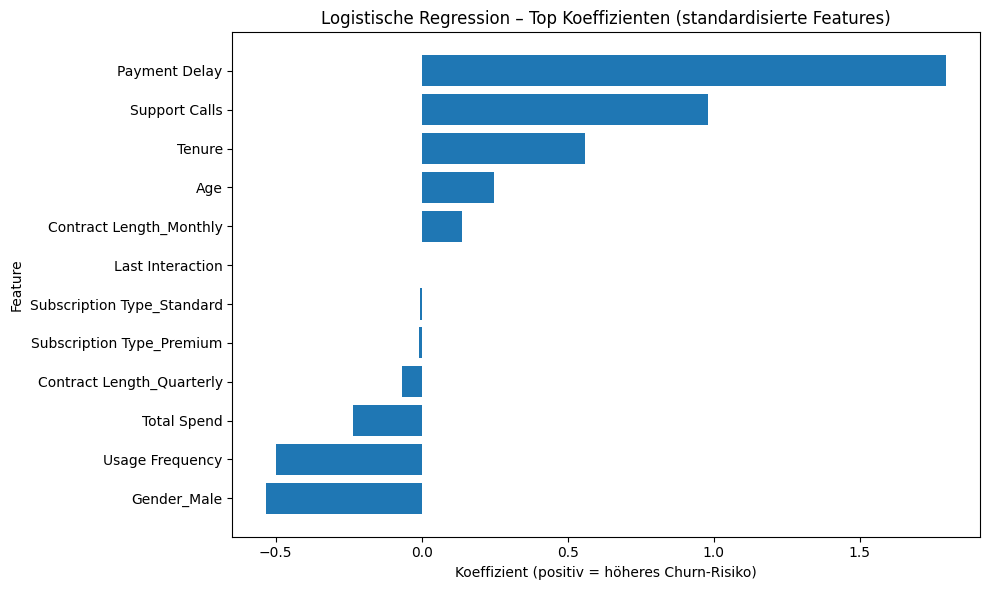

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# 1) Bestes Modell aus GridSearch
best_lr = grid.best_estimator_

# 2) Zugriff auf die Logistic Regression in der Pipeline
lr_model = best_lr.named_steps['lr']

# 3) Koeffizienten holen (Form: [1, n_features] -> flach machen)
coefs = lr_model.coef_.ravel()

# 4) Feature-Namen bestimmen (falls X_train DataFrame ist)
if hasattr(X_train, 'columns'):
    feature_names = X_train.columns.to_list()
else:
    feature_names = [f'Feature_{i}' for i in range(len(coefs))]

# 5) Odds Ratios berechnen
odds_ratios = np.exp(coefs)

# 6) Ergebnistabelle bauen
odds_df = pd.DataFrame({
    'Feature': feature_names,
    'Koeffizient': coefs,
    'Odds_Ratio': odds_ratios,
    'Abs_Koeffizient': np.abs(coefs)
}).sort_values('Abs_Koeffizient', ascending=False)

# Top 15 anzeigen
display(odds_df.head(12))

# 7) Plot: absolute Koeffizienten
plot_df = odds_df.sort_values('Koeffizient')

plt.figure(figsize=(10, 6))
plt.barh(plot_df['Feature'], plot_df['Koeffizient'])
plt.title(f'Logistische Regression – Top Koeffizienten (standardisierte Features)')
plt.xlabel('Koeffizient (positiv = höheres Churn-Risiko)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


### Interpretation der Koeffizienten

Die Analyse der Modellkoeffizienten bestätigt, dass insbesondere zahlungs- und servicebezogene Merkmale einen starken Einfluss auf die Abwanderungswahrscheinlichkeit haben.

Vor allem `Payment Delay` und `Support Calls` weisen deutlich positive Koeffizienten auf und gehen mit einem erhöhten Churn-Risiko einher. Demgegenüber wirken eine höhere Nutzungshäufigkeit sowie höhere Gesamtausgaben stabilisierend auf die Kundenbindung.

### Einordnung der Modellergebnisse

Der hohe Recall-Wert zeigt, dass ein Großteil der abwandernden Kunden korrekt identifiziert wird. Dies ist im Kontext von Customer Retention besonders relevant, da nicht erkannte Abwanderer mit direkten Umsatzverlusten verbunden sind.

Auch die Precision liegt auf einem soliden Niveau, sodass die Anzahl falsch-positiver Vorhersagen begrenzt bleibt. Der F1-Score deutet insgesamt auf eine ausgewogene Balance zwischen Sensitivität und Vorhersagegenauigkeit hin.


### Business-Einordnung der Einflussfaktoren

Die identifizierten Churn-Treiber liefern konkrete Ansatzpunkte für operative Maßnahmen im Kundenmanagement.

Insbesondere Zahlungsverspätungen und häufige Support-Anfragen können als Frühwarnsignale dienen, um gefährdete Kunden frühzeitig zu identifizieren und gezielt anzusprechen.

### Zusammenfassung

Die Analyse der Odds Ratios ermöglicht eine transparente Einordnung der Ergebnisse der logistischen Regression und ergänzt die reine Modellleistung um geschäftlich relevante Erkenntnisse.

Damit liefert das Modell nicht nur belastbare Vorhersagen, sondern auch konkrete Hinweise darauf, an welchen Stellen Maßnahmen zur Reduzierung der Kundenabwanderung ansetzen können.


### Einordnung als Baseline-Modell

Die logistische Regression dient in diesem Projekt als transparentes und gut interpretierbares Basismodell.

Im nächsten Schritt habe ich untersucht, ob komplexere Machine-Learning-Modelle wie Random Forest oder XGBoost eine zusätzliche Leistungssteigerung ermöglichen.


## Vergleich komplexerer Machine-Learning-Modelle

Nach der logistischen Regression als interpretierbarem Basismodell habe ich im nächsten Schritt leistungsstärkere, nichtlineare Machine-Learning-Modelle betrachtet.

Dabei ging es darum zu prüfen, ob sich die Vorhersagequalität weiter steigern lässt und ob komplexere Modelle zusätzliche Muster und Interaktionen in den Daten erfassen. Gleichzeitig habe ich den Trade-off zwischen Modellleistung und Interpretierbarkeit berücksichtigt.

### Random Forest

Als erstes nichtlineares Vergleichsmodell habe ich einen Random Forest eingesetzt. Das baumbasierte Ensemble-Verfahren kombiniert viele Entscheidungsbäume und liefert in der Regel robuste und stabile Vorhersagen.

Der Random Forest eignet sich besonders zur Modellierung nichtlinearer Zusammenhänge und dient hier als leistungsstarker Vergleich zur logistischen Regression.


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

model_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_rf = {
    'n_estimators': [200, 400],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 5],
    'class_weight': [None, 'balanced']
}

grid_rf = GridSearchCV(
    estimator=model_rf,
    param_grid=param_rf,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

print('Best params:', grid_rf.best_params_)
print('Recall:', recall_score(y_test, y_pred_rf))
print('Precision:', precision_score(y_test, y_pred_rf))
print('F1:', f1_score(y_test, y_pred_rf))
print('ROC-AUC:', roc_auc_score(y_test, y_proba_rf))


Best params: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 400}
Recall: 0.9975337060177574
Precision: 0.999341129962115
F1: 0.9984366000164568
ROC-AUC: 0.9999943725074747


### Auffällig hohe Modellleistung und Prüfung auf mögliche Informationsleckage

Das initiale Random-Forest-Modell erzielte auf den Testdaten eine außergewöhnlich hohe Modellleistung. Solch nahezu perfekte Kennzahlen sind in realen Anwendungsszenarien ungewöhnlich und können ein Hinweis darauf sein, dass einzelne Merkmale besonders starke oder möglicherweise problematische Informationen über die Zielvariable enthalten.

Aus diesem Grund habe ich im nächsten Schritt systematisch untersucht, wie stark sich die Modellleistung verändert, wenn einzelne Merkmale jeweils aus dem Feature-Set entfernt werden.


In [24]:
for col in ['Last Interaction', 'Payment Delay', 'Support Calls', 'Tenure', 'Age', 'Usage Frequency']:
    X_tr = X_train.drop(columns=[col])
    X_te = X_test.drop(columns=[col])

    model = RandomForestClassifier(
        n_estimators=400,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_tr, y_train)
    y_proba = model.predict_proba(X_te)[:, 1]

    print(col, roc_auc_score(y_test, y_proba))


Last Interaction 0.9999959820913583
Payment Delay 0.8515816739410983
Support Calls 0.9563369027045995
Tenure 0.9747509417033889
Age 0.9974122732005543
Usage Frequency 0.9861549766421546


### Untersuchung potenzieller Informationsleckage

Zur Untersuchung möglicher Informationsleckage habe ich den Einfluss einzelner Merkmale systematisch geprüft, indem ich diese jeweils aus dem Feature-Set entfernt und die resultierende Modellleistung erneut bewertet habe.

Dabei zeigte sich, dass insbesondere `Payment Delay` einen außergewöhnlich starken Einfluss auf die Modellleistung hat. Nach Entfernung dieses Merkmals sank die ROC-AUC von nahezu 1,0 auf etwa 0,85.

Dies allein beweist jedoch keine Informationsleckage. Entscheidend wäre, ob `Payment Delay` zum tatsächlichen Zeitpunkt einer Churn-Prognose bereits verfügbar wäre. Da der verwendete Datensatz keine eindeutige zeitliche Struktur enthält und wahrscheinlich synthetisch erzeugt wurde, lässt sich dies nicht abschließend beurteilen.

Die Entfernung anderer Merkmale wie `Support Calls`, `Tenure`, `Age`, `Usage Frequency` oder `Last Interaction` führte zu deutlich geringeren Veränderungen der Modellleistung. Diese Merkmale wurden daher für die weitere Modellierung beibehalten.



In [10]:
excluded_features = ["Payment Delay"]

X_train_final = X_train.drop(columns=excluded_features)
X_test_final  = X_test.drop(columns=excluded_features)


In [11]:

model_rf = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_rf = {
    'n_estimators': [200, 400],
    'max_depth': [10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 5],
    'class_weight': [None, 'balanced']
}

grid_rf = GridSearchCV(
    estimator=model_rf,
    param_grid=param_rf,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_rf.fit(X_train_final, y_train)

best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test_final)
y_proba_rf = best_rf.predict_proba(X_test_final)[:, 1]

print('Best params:', grid_rf.best_params_)
print('Recall:', recall_score(y_test, y_pred_rf))
print('Precision:', precision_score(y_test, y_pred_rf))
print('F1:', f1_score(y_test, y_pred_rf))
print('ROC-AUC:', roc_auc_score(y_test, y_proba_rf))


Best params: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 400}
Recall: 0.9830647813219335
Precision: 0.6896989272119045
F1: 0.8106569046166362
ROC-AUC: 0.8530405136378227


### Modellleistung nach Ausschluss des auffälligen Merkmals

Nach dem vorsorglichen Ausschluss von Payment Delay erzielt der Random Forest auf den Testdaten folgende Leistungskennzahlen:

- Recall: 0.98  
- Precision: 0.69  
- F1-Score: 0.81  
- ROC-AUC: 0.85  

Die Modellleistung liegt damit deutlich unter den zuvor nahezu perfekten Ergebnissen und erscheint für eine Churn-Klassifikation wesentlich realistischer.

Aufgrund des wahrscheinlich synthetischen Datensatzes und der fehlenden zeitlichen Struktur können die Kennzahlen jedoch nicht unmittelbar als reale Vorhersageleistung interpretiert werden.

### Einordnung der Ergebnisse

Der Random Forest erreicht auf dem vorliegenden Testdatensatz einen sehr hohen Recall-Wert und identifiziert dort nahezu alle abwandernden Kunden korrekt.Dies ist im Kontext der Kundenbindung besonders relevant, da nicht erkannte Abwanderer mit direkten Umsatzverlusten verbunden sind.

Die geringere Precision zeigt, dass das Modell auch Kunden als gefährdet einstuft, die letztlich nicht abwandern. Dieser Trade-off kann im Kontext der Kundenbindung sinnvoll sein, wenn das Übersehen potenziell abwandernder Kunden stärker gewichtet wird als zusätzliche False Positives.


### Einordnung im Vergleich zur logistischen Regression

Im Vergleich zur logistischen Regression zeigt der Random Forest eine höhere Sensitivität gegenüber abwandernden Kunden und ist besser geeignet, nichtlineare Zusammenhänge abzubilden.

Die logistische Regression bietet dagegen eine deutlich höhere Interpretierbarkeit der einzelnen Einflussfaktoren. Beide Modelle erfüllen damit unterschiedliche Zwecke und ergänzen sich sinnvoll im Rahmen der Churn-Analyse.


### Feature Importances des Random Forest

Um die Entscheidungslogik des Random Forest besser nachzuvollziehen, habe ich die Feature Importances analysiert. Diese zeigen, welche Merkmale den größten Beitrag zur Vorhersage der Kundenabwanderung leisten.

Im Gegensatz zur logistischen Regression basieren die Feature Importances auf der Reduktion der Unreinheit in den Entscheidungsbäumen und erlauben eine relative Einordnung der Einflussstärke einzelner Merkmale.


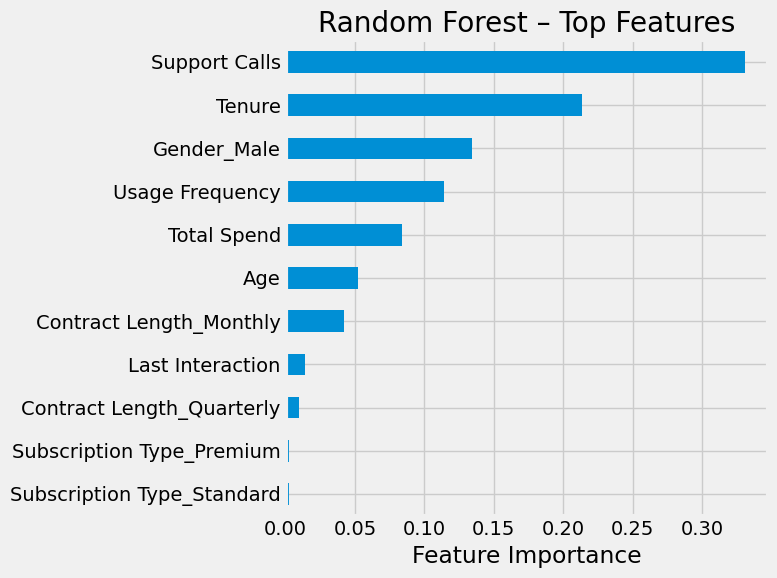

In [33]:
# Feature Importances aus dem Random Forest
rf_importances = pd.Series(
    best_rf.feature_importances_,
    index=X_train_final.columns
).sort_values(ascending=False)

plt.style.use('fivethirtyeight')
plt.figure(figsize=(8, 6))
rf_importances[::-1].plot(kind='barh')  # umdrehen, damit wichtigstes Feature oben ist
plt.xlabel('Feature Importance')
plt.title(f'Random Forest – Top Features')
plt.tight_layout()
plt.show()


### Interpretation der Feature Importances

Die Analyse der Feature Importances zeigt, dass insbesondere service- und nutzungsbezogene Merkmale einen starken Einfluss auf die Vorhersage der Kundenabwanderung haben.

`Support Calls` ist das wichtigste Merkmal, was darauf hindeutet, dass häufige Kontaktaufnahmen mit dem Kundenservice ein relevantes Abwanderungssignal darstellen. Auch die Vertragsdauer (`Tenure`) sowie das Nutzungsverhalten (`Usage Frequency`) spielen eine zentrale Rolle in der Modellentscheidung.

Demografische Merkmale und detaillierte Vertragsinformationen weisen dagegen einen vergleichsweise geringeren Einfluss auf die Vorhersage auf.

### Business-Einordnung der wichtigsten Merkmale

Die Ergebnisse unterstreichen die Bedeutung eines proaktiven Kundenmanagements. Insbesondere Kunden mit häufigen Support-Anfragen oder kurzer Vertragsdauer können frühzeitig als potenziell abwanderungsgefährdet identifiziert werden.

Durch die gemeinsame Betrachtung von Nutzungs- und Serviceinformationen lassen sich Abwanderungsrisiken früh erkennen und gezielte Maßnahmen zur Kundenbindung ableiten.


### ROC-Kurve – Random Forest

Zur Beurteilung der Trennschärfe des finalen Random-Forest-Modells habe ich die ROC-Kurve betrachtet.

Sie zeigt den Zusammenhang zwischen Sensitivität und Falsch-Positiv-Rate über unterschiedliche Schwellenwerte hinweg.


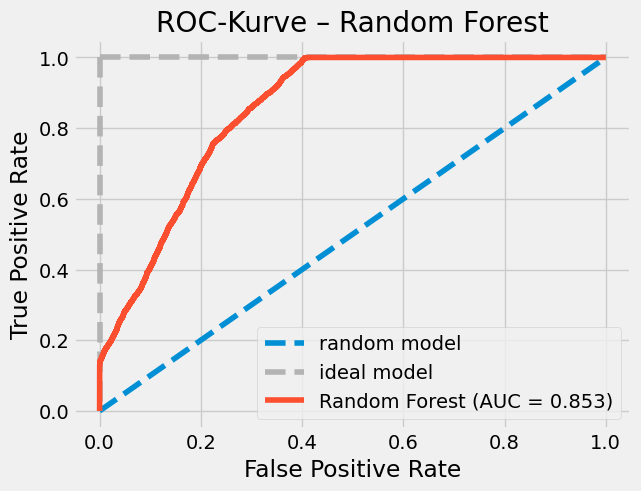

In [28]:
from sklearn.metrics import roc_curve, roc_auc_score

# ROC-Kurve berechnen
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba_rf)
roc_auc = roc_auc_score(y_test, y_proba_rf)

plt.style.use('fivethirtyeight')
# figure and axes intialisation
fig, ax = plt.subplots()
# reference lines
ax.plot([0, 1], ls = "--", label='random model') # blue diagonal
ax.plot([0, 0], [1, 0], c=".7", ls='--', label='ideal model') # grey vertical
ax.plot([1, 1], c=".7", ls='--') # grey horizontal
# roc curve
ax.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-Kurve – Random Forest')
ax.legend(loc='lower right')
ax.grid(True)


### Interpretation der ROC-Kurve

Die ROC-Kurve zeigt, dass das Random-Forest-Modell über alle Schwellenwerte hinweg klar oberhalb der Zufallslinie verläuft. Dies deutet auf eine gute Trennschärfe zwischen churnenden und nicht churnenden Kunden hin.

Mit einem ROC-AUC-Wert von etwa **0.85** erreicht das Modell eine solide Vorhersagequalität, die deutlich über dem Zufallsniveau liegt, ohne unrealistisch hohe Werte anzunehmen.

### Business-Einordnung

Eine gute Trennschärfe ist im Kontext von Customer Retention besonders relevant, da sich das Modell flexibel an unterschiedliche Kosten-Nutzen-Abwägungen anpassen lässt.

Abhängig vom strategischen Fokus, etwa der Vermeidung von Umsatzverlusten oder der Begrenzung von Retention-Kosten, kann der Entscheidungsschwellenwert entsprechend gewählt werden.


## Vergleichsmodell – Gradient Boosting (XGBoost)

Nach der Analyse des Random Forest habe ich im nächsten Schritt ein Gradient-Boosting-Modell eingesetzt. XGBoost ist ein leistungsfähiges Ensemble-Verfahren, das Entscheidungsbäume sequenziell aufbaut und Fehler vorheriger Modelle gezielt korrigiert.

Das Verfahren wird häufig in praxisnahen Data-Science-Anwendungen eingesetzt und zeigt insbesondere bei strukturierten Tabellendaten eine hohe Vorhersagequalität.

Ziel dieses Abschnitts war es zu prüfen, ob sich durch den Einsatz eines Boosting-Verfahrens eine weitere Leistungssteigerung gegenüber dem Random Forest erzielen lässt, ohne dabei die Modellvalidität zu beeinträchtigen.

### Umgang mit dem auffälligen Merkmal im XGBoost-Modell

Das im Random-Forest-Modell auffällige Merkmal Payment Delay wurde auch beim XGBoost-Modell vorsorglich ausgeschlossen.

Dadurch basieren Random Forest und XGBoost auf demselben reduzierten Feature-Set und können unter vergleichbaren Bedingungen bewertet werden.

Da für beide Modelle dieselben Eingangsmerkmale verwendet werden, wurde die zuvor durchgeführte Merkmalsanalyse nicht erneut vollständig wiederholt.


In [12]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

xgb_base = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    random_state=42,
    n_jobs=-1
)

param_grid_xgb = {
    'n_estimators': [200, 400],
    'max_depth': [2, 3, 5],
    'learning_rate': [0.01, 0.05],
}

grid_xgb = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid_xgb,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

# WICHTIG: leakage-bereinigte Features
grid_xgb.fit(X_train_final, y_train)

best_xgb = grid_xgb.best_estimator_
print('Best XGB Parameters:', grid_xgb.best_params_)

y_pred_xgb = best_xgb.predict(X_test_final)
y_proba_xgb = best_xgb.predict_proba(X_test_final)[:, 1]

print('\nClassification Report:')
print(classification_report(y_test, y_pred_xgb))

print('ROC-AUC:', roc_auc_score(y_test, y_proba_xgb))

print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred_xgb))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best XGB Parameters: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.64      0.75      6793
           1       0.70      0.94      0.80      6082

    accuracy                           0.78     12875
   macro avg       0.81      0.79      0.78     12875
weighted avg       0.81      0.78      0.77     12875

ROC-AUC: 0.8520148940484752

Confusion Matrix:
[[4323 2470]
 [ 383 5699]]


### Einordnung der XGBoost-Ergebnisse

Das XGBoost-Modell erreicht eine Modellleistung, die insgesamt mit der des Random Forest vergleichbar ist. Insbesondere der hohe Recall-Wert zeigt, dass auch mit einem Boosting-Verfahren ein Großteil der abwandernden Kunden korrekt identifiziert werden kann.

Auf eine weitergehende Hyperparameter-Optimierung habe ich bewusst verzichtet, da die erzielte Modellleistung stabil ist und zusätzliche Komplexität voraussichtlich keinen nennenswerten Mehrwert gebracht hätte.


### Feature Importances – XGBoost

Um die Entscheidungslogik des XGBoost-Modells besser nachzuvollziehen, habe ich die Feature Importances analysiert. Diese zeigen, welche Merkmale den größten Beitrag zur Vorhersage der Kundenabwanderung leisten.

Die Feature Importances geben dabei die **relative Bedeutung** einzelner Merkmale an, erlauben jedoch keine direkte Aussage über die **Richtung** des Effekts (positiv oder negativ).


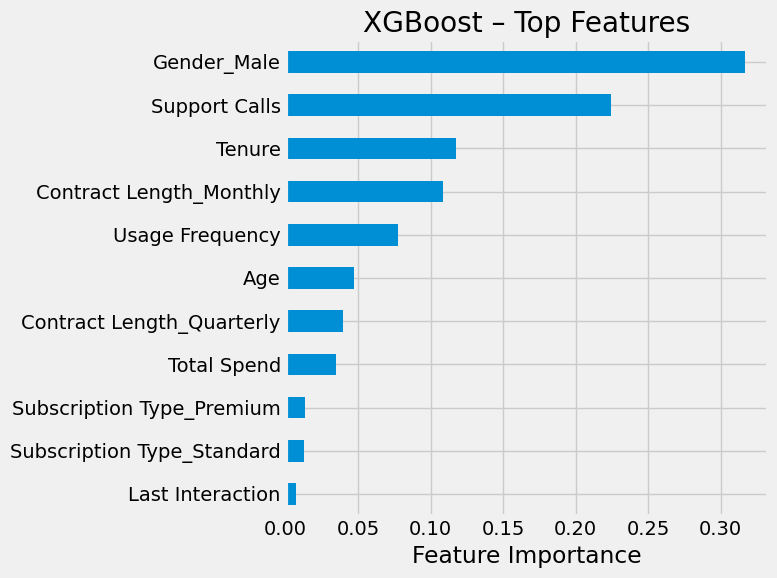

In [32]:
# Feature Importances aus dem trainierten (besten) XGBoost-Modell
xgb_importances = pd.Series(
    best_xgb.feature_importances_,
    index=X_train_final.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
xgb_importances[::-1].plot(kind='barh')  # umdrehen, damit wichtigstes Feature oben ist
plt.xlabel('Feature Importance')
plt.title('XGBoost – Top Features')
plt.tight_layout()
plt.show()


### Interpretation der Feature Importances (XGBoost)

Die Feature-Importance-Analyse des XGBoost-Modells zeigt, dass sowohl demografische als auch service- und nutzungsbezogene Merkmale einen relevanten Beitrag zur Vorhersage der Kundenabwanderung leisten.

Auffällig ist, dass das Merkmal `Gender_Male` im XGBoost-Modell eine hohe relative Bedeutung aufweist. Dies deutet darauf hin, dass demografische Faktoren im Zusammenspiel mit weiteren Kundenmerkmalen eine Rolle für die Modellentscheidung spielen können.

Darüber hinaus sind insbesondere servicebezogene Variablen wie `Support Calls` sowie die Dauer der Kundenbeziehung (`Tenure`) von hoher Bedeutung. Auch das Nutzungsverhalten (`Usage Frequency`) trägt messbar zur Unterscheidung zwischen churnenden und nicht churnenden Kunden bei.

Vertragsbezogene Merkmale weisen insgesamt einen moderaten, aber konsistenten Einfluss auf die Modellentscheidung auf.

### Business-Einordnung der wichtigsten Merkmale (XGBoost)

Die Ergebnisse unterstreichen die Bedeutung einer ganzheitlichen Betrachtung verschiedener Kundenmerkmale. Insbesondere service- und nutzungsbezogene Informationen liefern wertvolle Hinweise auf potenzielle Abwanderungsrisiken.

Demografische Merkmale können zur Segmentierung von Kundengruppen beitragen, sollten jedoch primär im Zusammenspiel mit verhaltensbezogenen Daten interpretiert werden. Maßnahmen zur Kundenbindung sollten sich vor allem auf beeinflussbare Faktoren wie Support-Interaktionen oder die Nutzungsintensität konzentrieren.


### Logistische Regression – Re-Training mit reduziertem Feature-Set

Um einen fairen Vergleich zwischen den Modellen zu ermöglichen, habe ich die logistische Regression erneut mit dem gleichen reduzierten Feature-Set trainiert, das auch für Random Forest und XGBoost verwendet wurde.

In [15]:
# Pipeline: erst Skalierung, dann Modell
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(random_state=42))
])

# Parametergrid (Pipeline-konform!)
param_grid = {
    'lr__solver': ['liblinear', 'saga'],
    'lr__penalty': ['l1', 'l2'],
    'lr__C': [0.01, 0.1, 1, 10, 100],
    'lr__class_weight': [None, 'balanced'],
    'lr__max_iter': [1000]
}

grid = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid.fit(X_train_final, y_train)

best_lr = grid.best_estimator_

y_pred_lr = best_lr.predict(X_test_final)
y_proba_lr = best_lr.predict_proba(X_test_final)[:, 1]

print('Best params:', grid.best_params_)
print('Recall:', recall_score(y_test, y_pred_lr))
print('Precision:', precision_score(y_test, y_pred_lr))
print('F1:', f1_score(y_test, y_pred_lr))
print('ROC-AUC:', roc_auc_score(y_test, y_proba_lr))


Best params: {'lr__C': 0.01, 'lr__class_weight': 'balanced', 'lr__max_iter': 1000, 'lr__penalty': 'l1', 'lr__solver': 'liblinear'}
Recall: 0.6923709306149293
Precision: 0.6538819875776397
F1: 0.6725762657722408
ROC-AUC: 0.7478801538210336


### Einordnung der logistischen Regression (reduziertes Feature-Set)

Nach dem Re-Training auf dem reduzierten Feature-Set zeigt die logistische Regression eine solide Baseline-Performance, bleibt auf dem vorliegenden Datensatz jedoch hinter den nichtlinearen Ensemble-Modellen zurück.

Dies lässt sich unter anderem dadurch erklären, dass die logistische Regression Zusammenhänge linear in den Log-Odds modelliert und komplexe nichtlineare Muster oder Interaktionen zwischen Merkmalen nicht automatisch abbildet.

Die Ergebnisse dienen im weiteren Verlauf als Referenz für den fairen Modellvergleich mit Random Forest und XGBoost.


## Modellvergleich

### ROC-Kurven-Vergleich

Zur vergleichenden Bewertung der Modellleistung habe ich die ROC-Kurven der logistischen Regression, des Random Forests und des XGBoost-Modells gemeinsam dargestellt.

Alle Modelle basieren dabei auf dem gleichen reduzierten Feature-Set.


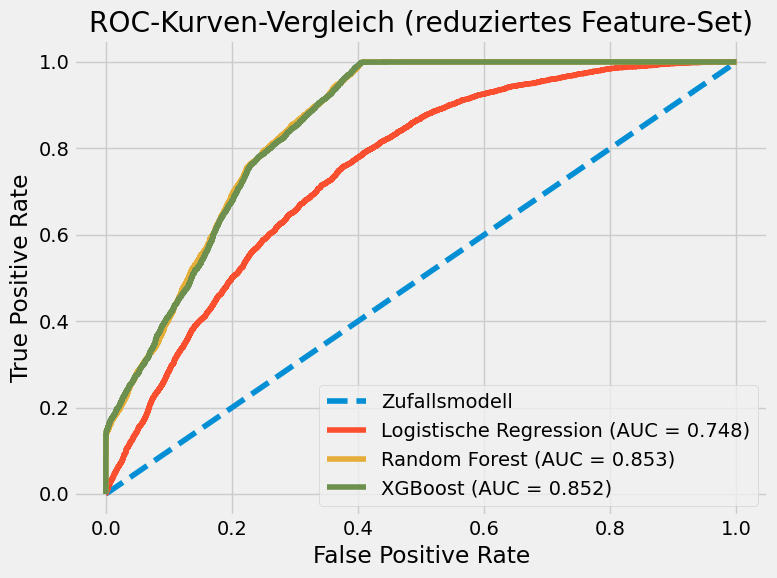

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
# ROC-Kurven + AUC
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_proba_xgb)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)

roc_auc_rf = roc_auc_score(y_test, y_proba_rf)
roc_auc_xgb = roc_auc_score(y_test, y_proba_xgb)
roc_auc_lr = roc_auc_score(y_test, y_proba_lr)

plt.style.use('fivethirtyeight')
fig, ax = plt.subplots(figsize=(8, 6))

# Zufallsmodell (Diagonale)
ax.plot([0, 1], [0, 1], linestyle="--", label='Zufallsmodell')

# Modelle
ax.plot(fpr_lr, tpr_lr, label=f"Logistische Regression (AUC = {roc_auc_lr:.3f})")
ax.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_rf:.3f})")
ax.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {roc_auc_xgb:.3f})")

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC-Kurven-Vergleich (reduziertes Feature-Set)')
ax.legend(loc='lower right')
ax.grid(True)
plt.tight_layout()
plt.show()


### Interpretation des ROC-Kurven-Vergleichs

Der Vergleich der ROC-Kurven zeigt klare Leistungsunterschiede zwischen den drei betrachteten Modellen.

Die logistische Regression erreicht mit einer ROC-AUC von **0.75** eine solide Baseline-Leistung, bleibt jedoch über weite Bereiche der Kurve deutlich hinter den beiden Ensemble-Modellen zurück. Dies deutet darauf hin, dass lineare Entscheidungsgrenzen nur einen Teil der zugrunde liegenden Zusammenhänge abbilden können.

Sowohl der Random Forest (**AUC = 0.85**) als auch das XGBoost-Modell (**AUC = 0.85**) weisen eine deutlich höhere Trennschärfe auf. Bereits bei niedrigen False-Positive-Raten erzielen beide Modelle eine hohe True-Positive-Rate, was für den praktischen Einsatz im Customer-Retention-Kontext besonders relevant ist.

Die nahezu deckungsgleichen ROC-Kurven von Random Forest und XGBoost verdeutlichen, dass beide Modelle eine vergleichbare Vorhersagequalität liefern. Während der Random Forest eine minimal bessere Performance zeigt, arbeitet XGBoost mit einer ähnlichen Güte bei höherer Modellkomplexität.

Insgesamt bestätigen die Ergebnisse, dass nichtlineare Ensemble-Modelle für die Identifikation abwanderungsgefährdeter Kunden deutlich besser geeignet sind als die logistische Regression. Diese bleibt jedoch als interpretierbares Referenzmodell weiterhin wertvoll, insbesondere zur Erklärung zentraler Einflussfaktoren.


## Modellvergleich – Kennzahlenübersicht

Zur übersichtlichen Bewertung der Modellleistung habe ich die wichtigsten Performance-Kennzahlen (Recall, Precision, F1-Score und ROC-AUC) für alle drei Verfahren in einer Tabelle zusammengefasst.

Alle Modelle wurden dabei auf dem gleichen reduzierten Feature-Set evaluiert.


In [36]:
# --- Kennzahlen berechnen ---
results = pd.DataFrame([
    {
        'Modell': 'Logistische Regression',
        'Recall': recall_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'F1': f1_score(y_test, y_pred_lr),
        'ROC-AUC': roc_auc_score(y_test, y_proba_lr),
    },
    {
        'Modell': 'Random Forest',
        'Recall': recall_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf),
        'F1': f1_score(y_test, y_pred_rf),
        'ROC-AUC': roc_auc_score(y_test, y_proba_rf),
    },
    {
        'Modell': 'XGBoost',
        'Recall': recall_score(y_test, y_pred_xgb),
        'Precision': precision_score(y_test, y_pred_xgb),
        'F1': f1_score(y_test, y_pred_xgb),
        'ROC-AUC': roc_auc_score(y_test, y_proba_xgb),
    },
])

# formatieren
results_formatted = results.copy()
for col in ['Recall', 'Precision', 'F1', 'ROC-AUC']:
    results_formatted[col] = results_formatted[col].map(lambda x: f'{x:.3f}')

results_formatted


,Modell,Recall,Precision,F1,ROC-AUC
0,Logistische Regression,0.692,0.654,0.673,0.748
1,Random Forest,0.983,0.690,0.811,0.853
2,XGBoost,0.937,0.698,0.800,0.852


### Interpretation der Vergleichstabelle

Die Vergleichstabelle zeigt klare Leistungsunterschiede zwischen den eingesetzten Modellen:

- **Logistische Regression** weist die geringste Modellleistung auf. Insbesondere der Recall ist deutlich niedriger, was bedeutet, dass ein relevanter Anteil tatsächlich abwandernder Kunden nicht erkannt wird. Das Modell eignet sich daher vor allem als **Baseline** und zur **Erklärung von Zusammenhängen**, weniger für operative Vorhersagezwecke.

- **Random Forest** erzielt insgesamt die beste Performance. Mit einem sehr hohen **Recall (0.98)** identifiziert das Modell nahezu alle abwandernden Kunden korrekt. Die **ROC-AUC von 0.85** bestätigt eine gute Trennschärfe. Die geringere Precision weist auf bewusst in Kauf genommene Fehlalarme hin, was im Kontext von Kundenbindungsmaßnahmen häufig akzeptabel ist.

- **XGBoost** zeigt eine vergleichbare Modellqualität zum Random Forest, mit einer leicht geringeren ROC-AUC. Der Recall fällt etwas niedriger aus, die Precision ist jedoch ähnlich. Damit stellt XGBoost eine leistungsfähige Alternative dar, insbesondere wenn eine feinere Modellsteuerung oder spätere Erweiterungen vorgesehen sind.

**Zusammenfassend** bietet der Random Forest in diesem Projekt das beste Verhältnis aus Sensitivität und Trennschärfe, während die logistische Regression weiterhin als gut interpretierbares Referenzmodell dient.


## Gesamtauswertung und Modellentscheidung

Im Rahmen dieses Projekts wurden drei unterschiedliche Modellansätze zur Vorhersage von Customer Churn entwickelt und miteinander verglichen:

- Logistische Regression (Baseline-Modell)
- Random Forest
- XGBoost

Alle Modelle wurden auf dem gleichen bereinigten Feature-Set trainiert, um eine faire Vergleichbarkeit sicherzustellen.

### Vergleich der Modellleistung

Der Modellvergleich zeigt deutliche Unterschiede hinsichtlich Vorhersagegüte und Interpretierbarkeit:

- Die **logistische Regression** erreicht eine solide, aber deutlich geringere Trennschärfe (ROC-AUC ≈ 0.75). Sie dient primär als transparentes Referenzmodell und ermöglicht eine klare Interpretation einzelner Einflussfaktoren über Koeffizienten und Odds Ratios.

- Der **Random Forest** erzielt die beste Gesamtperformance (ROC-AUC ≈ 0.85 bei sehr hohem Recall). Das Modell identifiziert nahezu alle abwandernden Kunden korrekt, weist jedoch eine geringere Precision auf. Nach der Bereinigung potenzieller Informationsleckage liefert es realistische und robuste Ergebnisse.

- **XGBoost** erreicht eine vergleichbare Trennschärfe wie der Random Forest, zeigt jedoch eine etwas geringere Stabilität bei gleichzeitig höherer Modellkomplexität.

### Modellentscheidung

Für den **operativen Einsatz** wird der **Random Forest** als geeignetstes Modell ausgewählt.

Begründung:
- Hohe Sensitivität gegenüber abwandernden Kunden (sehr hoher Recall)
- Gute Trennschärfe bei realistischen Leistungskennzahlen
- Fähigkeit zur Abbildung nichtlinearer Zusammenhänge
- Robuste Performance nach expliziter Leakage-Bereinigung

Die **logistische Regression** wird bewusst **nicht als operatives Modell** eingesetzt, sondern als **Erklär- und Kommunikationsmodell** genutzt.

Begründung:
- Hohe Interpretierbarkeit der Modellparameter
- Transparente Darstellung zentraler Churn-Treiber
- Gute Eignung für die Kommunikation mit Fachabteilungen und Management

### Trade-off: Interpretierbarkeit vs. Performance

Die Ergebnisse verdeutlichen einen klassischen Zielkonflikt:

- Die logistische Regression bietet eine hohe Nachvollziehbarkeit, jedoch eine begrenzte Vorhersageleistung.
- Ensemble-Modelle wie Random Forest und XGBoost liefern eine deutlich bessere Performance, sind jedoch weniger transparent.

Durch die **Kombination beider Modelltypen** lässt sich sowohl eine leistungsstarke Vorhersage als auch eine verständliche Erklärung der Kundenabwanderung erreichen.


## Handlungsempfehlungen für das Kundenmanagement

Auf Basis der explorativen Datenanalyse sowie der Ergebnisse der Modellierung lassen sich konkrete, datengetriebene Maßnahmen zur Reduzierung der Kundenabwanderung ableiten.

Die Empfehlungen konzentrieren sich auf Merkmale, die sowohl in der logistischen Regression als auch in den Ensemble-Modellen als besonders relevant identifiziert wurden.

### 1. Proaktive Betreuung bei hoher Support-Interaktion

Das Merkmal `Support Calls` zählt in allen Modellen zu den stärksten Prädiktoren für Customer Churn.

**Empfehlungen:**
- Kunden mit häufigen Support-Kontakten frühzeitig identifizieren  
- Automatisierte Eskalation an erfahrene Service-Mitarbeiter  
- Analyse wiederkehrender Support-Gründe zur gezielten Prozessverbesserung  
- Proaktive Kontaktaufnahme nach mehreren Support-Tickets  

**Business-Nutzen:**  
Reduktion von Frustration, Verbesserung der Kundenzufriedenheit und präventive Vermeidung von Abwanderung.

---

### 2. Frühzeitige Maßnahmen bei kurzer Kundenbindung (Tenure)

Eine kurze Vertrags- bzw. Kundenlaufzeit (`Tenure`) geht mit einem erhöhten Abwanderungsrisiko einher.

**Empfehlungen:**
- Intensivierung strukturierter Onboarding-Programme  
- Persönliche Check-ins in den ersten Monaten  
- Gezielte Willkommensangebote oder begleitende Tutorials  
- Monitoring des Nutzungsverhaltens in der frühen Kundenphase  

**Business-Nutzen:**  
Stabilisierung der Kundenbeziehung in der kritischen Anfangsphase und Erhöhung der langfristigen Kundenbindung.

---

### 3. Nutzungssignale aktiv überwachen (Usage Frequency)

Eine geringe Nutzungsfrequenz stellt ein frühes Warnsignal für potenzielle Abwanderung dar.

**Empfehlungen:**
- Definition klarer Schwellenwerte für niedrige Nutzung  
- Automatisierte Reminder oder personalisierte Nutzungshinweise  
- Produkt- oder Feature-Empfehlungen auf Basis des individuellen Nutzungsverhaltens  
- Einsatz von A/B-Tests zur Reaktivierung inaktiver Nutzer  

**Business-Nutzen:**  
Steigerung der Produktbindung und frühzeitige Reaktivierung abwanderungsgefährdeter Kunden.

---

### 4. Vertragliche Bindung gezielt steuern

Die Vertragslaufzeit zeigt einen messbaren Einfluss auf die Abwanderungswahrscheinlichkeit.

**Empfehlungen:**
- Schaffung gezielter Anreize für längere Vertragslaufzeiten  
- Frühzeitige Verlängerungsangebote vor Vertragsende  
- Angebot flexibler Upgrade-Optionen als Alternative zur Kündigung  
- Segmentierte Angebote je Vertragsmodell  

**Business-Nutzen:**  
Reduktion kündigungsbedingter Abwanderung und bessere Planbarkeit der Umsätze.

---

### 5. Segmentierung statt Pauschalmaßnahmen

Die Modellergebnisse zeigen, dass Kundenabwanderung durch das Zusammenspiel mehrerer Faktoren entsteht und nicht auf einzelne Merkmale reduziert werden kann.

**Empfehlungen:**
- Kombination mehrerer Risikosignale zu einem aggregierten Churn-Score  
- Segmentierung in Hoch-, Mittel- und Niedrigrisiko-Kunden  
- Ableitung unterschiedlicher Maßnahmen je Risikoklasse  
- Einsatz des Random-Forest-Modells als operatives Frühwarnsystem  

**Business-Nutzen:**  
Effizienter Ressourceneinsatz und höhere Wirksamkeit von Kundenbindungsmaßnahmen.

---

### Fazit

Durch die Kombination aus prädiktiver Modellierung und gezielten geschäftlichen Maßnahmen können Abwanderungsrisiken frühzeitig erkannt und aktiv reduziert werden.

Das entwickelte Modell liefert damit nicht nur Prognosen, sondern eine fundierte Entscheidungsgrundlage für ein datengetriebenes Customer-Relationship-Management.


## Limitationen und Annahmen

Trotz der insgesamt guten Modellleistung unterliegt dieses Projekt mehreren Annahmen und Einschränkungen, die bei der Interpretation der Ergebnisse berücksichtigt werden sollten.

### 1. Synthetischer Datensatz

Der verwendete Datensatz ist höchstwahrscheinlich synthetisch generiert. Reale Komplexitäten, Rauschen sowie unerwartete Verhaltensmuster echter Kunden können dadurch nur eingeschränkt abgebildet werden.

**Implikation:**  
Die absoluten Modellkennzahlen sind daher weniger aussagekräftig als die methodische Vorgehensweise und die im Datensatz identifizierten Einflussfaktoren.

---

### 2. Vereinfachte zeitliche Struktur

Die Daten enthalten keine explizite Zeitachse. Bei Merkmalen wie `Payment Delay` oder `Last Interaction` ist daher nicht eindeutig nachvollziehbar, zu welchem Zeitpunkt sie im Verhältnis zum Churn-Ereignis erhoben wurden.

Dadurch lässt sich nicht abschließend beurteilen, ob einzelne Merkmale zum tatsächlichen Zeitpunkt einer Churn-Prognose bereits verfügbar gewesen wären. Eine mögliche Informationsleckage kann daher nicht vollständig ausgeschlossen werden.

---

### 3. Keine explizite Kostenfunktion

Die Modellbewertung basiert auf statistischen Kennzahlen wie Recall, Precision, F1-Score und ROC-AUC. Konkrete betriebswirtschaftliche Kosten für False Positives und False Negatives wurden nicht berücksichtigt.

**Implikation:**  
In einem realen Anwendungsszenario müsste die Wahl des optimalen Entscheidungsschwellenwerts anhand betriebswirtschaftlicher Zielgrößen erfolgen.

---

### 4. Keine Zeitreihen- oder Survival-Analyse

Das Problem wurde als klassisches binäres Klassifikationsproblem modelliert. Zeitabhängige Effekte, etwa die Dauer bis zur Abwanderung, wurden nicht explizit berücksichtigt.

Mögliche Erweiterungen wären Survival-Modelle oder andere zeitabhängige Modellansätze.

---

### 5. Vereinfachte Feature-Generierung

Die verwendeten Features basieren auf aggregierten Kennzahlen. In realen Szenarien könnten detailliertere Nutzungs-, Interaktions- oder Verlaufsdaten zusätzliche Prognosekraft liefern.


## Fazit & Ausblick

Ziel dieses Projekts war es, Customer Churn mithilfe datengetriebener Methoden vorherzusagen, zentrale Einflussfaktoren zu analysieren und daraus mögliche Handlungsempfehlungen abzuleiten.

Im Rahmen eines strukturierten Data-Science-Workflows wurden die Daten zunächst explorativ analysiert und anschließend mehrere Modelle, darunter logistische Regression, Random Forest und XGBoost, entwickelt und systematisch miteinander verglichen. Ein besonderer Fokus lag auf der Untersuchung ungewöhnlich hoher Modellleistungen und möglicher Informationsleckage, um die Ergebnisse realistischer einordnen zu können.

Im vorliegenden Modellvergleich zeigen die Ensemble-Modelle eine höhere Trennschärfe als die logistische Regression. Der Random Forest erzielt dabei die stärkste Gesamtperformance, während die logistische Regression zusätzliche Vorteile hinsichtlich Interpretierbarkeit und Nachvollziehbarkeit der Einflussfaktoren bietet.

### Ausblick

Für einen realen produktiven Einsatz wären mehrere Weiterentwicklungen sinnvoll:

- Integration einer expliziten Kostenfunktion zur optimalen Wahl des Entscheidungsschwellenwerts
- Erweiterung um zeitliche Komponenten, etwa durch Survival-Analysen oder sequenzielle Modellansätze 
- Nutzung detaillierterer Nutzungs- und Interaktionsdaten 
- Validierung auf realen, zeitlich strukturierten Kundendaten
- regelmäßiges Re-Training und Monitoring des Modells zur Sicherstellung langfristiger Stabilität  

Insgesamt zeigt das Projekt exemplarisch, wie datengetriebene Modelle zur Analyse von Kundenabwanderung eingesetzt werden können und welche methodischen Prüfungen für eine realistische Bewertung der Modellleistung wichtig sind.
